# 14 — Final Validation

**Milestone 4 · Task 15.** Perform final testing of the machine learning
model and the recommendation prototype. Check that the results are
consistent, reasonable, and based only on information available at campaign
launch.

Every check below states its pass condition **before** the result is shown,
and a check that fails is reported as a failure. The notebook ends with a
single table of all checks.

In [1]:
import sys
import json
import warnings
from collections import Counter
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import roc_auc_score

from src.features import LEAKY_COLUMNS, build_model_matrix
from src.modeling import align_columns, FINAL_MODEL_NAME, make_final_model
from src.evaluation import evaluate, majority_class_baseline
from src.prepare import load_splits
from src.recommend import (
    Recommender, RAW_COLUMNS, NOT_AT_LAUNCH, BANDS, MIN_GAIN, GOAL_FACTORS,
    DURATION_TARGETS, TIER_TARGETS, MIN_TIER_ADDITION, DEFAULT_DURATION,
    campaign_from_row, EXTRA,
)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")

splits = load_splits("..")
train, test = splits["random"]
train_c, test_c = splits["chronological"]
rec = Recommender.fit(train, test=test)

checks = []
def check(name, passed, detail):
    checks.append({"check": name, "passed": bool(passed), "detail": detail})
    print(f"{'PASS' if passed else 'FAIL'}  {name}\n      {detail}")

## 15.1 Is everything based on launch-time information only?

**Pass condition:** no post-launch column among the model's features, no
post-launch field among the prototype's inputs, and every post-launch field
refused if offered.

In [2]:
leak_names = {"pledged", "backers", "comments", "updates", "funded", "status", "success"}
bad = [c for c in rec.columns
       if c in LEAKY_COLUMNS or c.split("_")[0] in leak_names]
check("No post-launch column among the model's features", not bad,
      f"{len(rec.columns)} features inspected; offending: {bad or 'none'}")

post_launch = NOT_AT_LAUNCH | {"funded_date", "end_date"}
overlap = sorted(set(RAW_COLUMNS) & post_launch)
check("No post-launch field among the prototype's inputs", not overlap,
      f"inputs are {RAW_COLUMNS}; overlap: {overlap or 'none'}")

camp = dict(goal=10000, duration=40, reward_tiers=[10, 25, 50],
            category="Film & Video", subcategory="Documentary", state="CA")
refused = 0
for k in sorted(NOT_AT_LAUNCH):
    try:
        rec.validate({**camp, k: 1})
    except ValueError:
        refused += 1
check("Every post-launch field is refused", refused == len(NOT_AT_LAUNCH),
      f"{refused} of {len(NOT_AT_LAUNCH)} refused: {sorted(NOT_AT_LAUNCH)}")

drift = ((train["end_date"] - pd.to_timedelta(train["duration"], unit="D"))
         - train["launch_date"]).abs().max()
check("Timing features come from the launch date, not the end date", drift == pd.Timedelta(0),
      f"launch_date = end_date - duration holds exactly (max deviation {drift})")

sc = rec.self_check()
check("What-if engine rebuilds the training matrix exactly", sc["matrix_reproduced"] and sc["tier_round_trip_ok"],
      f"{sc['rows_checked']} rows re-featurised from raw inputs; max difference {sc['max_abs_difference']}")

PASS  No post-launch column among the model's features
      137 features inspected; offending: none
PASS  No post-launch field among the prototype's inputs
      inputs are ['goal', 'duration', 'levels', 'reward_levels', 'category', 'subcategory', 'state_raw', 'city', 'launch_date', 'name']; overlap: none
PASS  Every post-launch field is refused
      7 of 7 refused: ['backers', 'comments', 'funded_percentage', 'pledged', 'status', 'success', 'updates']
PASS  Timing features come from the launch date, not the end date
      launch_date = end_date - duration holds exactly (max deviation 0 days 00:00:00)
PASS  What-if engine rebuilds the training matrix exactly
      2000 rows re-featurised from raw inputs; max difference 0.0


## 15.2 Does the final model reproduce Milestone 3?

**Pass condition:** accuracy, F1 and ROC-AUC within 0.003 of the values
recorded in the Milestone 3 model card (`reports/m3_model_card.json`, written
by notebook 09). On the later-period test, accuracy within 3 points of the
random split.

In [3]:
X_te, y_te = build_model_matrix(test, "launch_only", extra_numeric=EXTRA)
X_te = align_columns(rec.X_train, X_te)
perf = evaluate(rec.model, X_te, y_te, label=FINAL_MODEL_NAME,
                feature_set="launch_only", split="random")

rec_c = Recommender.fit(train_c, test=test_c)
Xc, yc = build_model_matrix(test_c, "launch_only", extra_numeric=EXTRA)
Xc = align_columns(rec_c.X_train, Xc)
perf_c = evaluate(rec_c.model, Xc, yc, label=FINAL_MODEL_NAME,
                  feature_set="launch_only", split="chronological")
floor = majority_class_baseline(train["success"], test["success"])
floor_c = majority_class_baseline(train_c["success"], test_c["success"])

table = pd.concat([floor, perf, floor_c.assign(split="chronological"), perf_c], ignore_index=True)
table.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Majority class,—,—,0.5473,0.5473,1.0000,0.7074,0.5000
1,Random Forest (tuned + calibrated),launch_only,random,0.7187,0.7121,0.8160,0.7605,0.7800
2,Majority class,—,chronological,0.5349,0.5349,1.0000,0.6970,0.5000
3,Random Forest (tuned + calibrated),launch_only,chronological,0.7199,0.7076,0.8117,0.7561,0.7896


In [4]:
_card = json.loads(Path("../reports/m3_model_card.json").read_text())
ref = {k: _card[k] for k in ("accuracy", "f1", "roc_auc")}
diffs = {k: abs(float(perf[k].iloc[0]) - v) for k, v in ref.items()}
check("Reproduces the Milestone 3 model (random split)", all(d <= 0.003 for d in diffs.values()),
      "differences from Milestone 3: " + ", ".join(f"{k} {d:.4f}" for k, d in diffs.items()))
gap = abs(float(perf["accuracy"].iloc[0]) - float(perf_c["accuracy"].iloc[0]))
check("Holds up on later campaigns (chronological split)", gap <= 0.03,
      f"accuracy {float(perf['accuracy'].iloc[0]):.3f} random vs {float(perf_c['accuracy'].iloc[0]):.3f} "
      f"chronological (gap {gap * 100:.1f} pts); chronological floor is {float(floor_c['accuracy'].iloc[0]):.3f}")

PASS  Reproduces the Milestone 3 model (random split)
      differences from Milestone 3: accuracy 0.0000, f1 0.0000, roc_auc 0.0000
PASS  Holds up on later campaigns (chronological split)
      accuracy 0.719 random vs 0.720 chronological (gap 0.1 pts); chronological floor is 0.535


## 15.3 Are the probabilities calibrated?

**Pass condition:** in every decile of predicted probability the observed
success rate is within 5 points of the prediction, on both splits; and the
three risk bands have increasing observed success.

In [5]:
def calibration(p, y, bins=10):
    q = pd.qcut(p, bins, duplicates="drop")
    c = (pd.DataFrame({"p": p, "y": y}).groupby(q, observed=True)
         .agg(predicted=("p", "mean"), observed=("y", "mean"), n=("y", "size")))
    c["gap_pp"] = (c["observed"] - c["predicted"]) * 100
    return c

cal_r = calibration(rec.holdout_p, rec.holdout_y)
cal_c = calibration(rec_c.holdout_p, rec_c.holdout_y)
print("Random split — largest decile gap:", round(cal_r["gap_pp"].abs().max(), 1), "pts")
print("Chronological split — largest decile gap:", round(cal_c["gap_pp"].abs().max(), 1), "pts")
print(f"\nShare of campaigns that succeeded: earlier period {train_c['success'].mean():.1%}, "
      f"later period {test_c['success'].mean():.1%}")
cal_c.round(3)

Random split — largest decile gap: 3.4 pts
Chronological split — largest decile gap: 6.5 pts

Share of campaigns that succeeded: earlier period 55.0%, later period 53.5%


,predicted,observed,n,gap_pp
"(0.062299999999999994, 0.158]",0.115,0.049,768,-6.544
"(0.158, 0.271]",0.212,0.233,768,2.117
"(0.271, 0.399]",0.334,0.329,767,-0.510
"(0.399, 0.514]",0.457,0.460,768,0.279
"(0.514, 0.6]",0.559,0.546,767,-1.275
"(0.6, 0.671]",0.636,0.629,768,-0.663
"(0.671, 0.726]",0.699,0.677,767,-2.267
"(0.726, 0.774]",0.751,0.741,768,-0.967
"(0.774, 0.819]",0.795,0.806,767,1.050
"(0.819, 0.903]",0.847,0.880,768,3.284


In [6]:
check("Calibrated within 5 points per decile (random split)", cal_r["gap_pp"].abs().max() <= 5,
      f"largest gap {cal_r['gap_pp'].abs().max():.1f} pts")
check("Calibrated within 5 points per decile (chronological split)", cal_c["gap_pp"].abs().max() <= 5,
      f"largest gap {cal_c['gap_pp'].abs().max():.1f} pts")
rates = [rec.band_rates[n]["observed_rate"] for _, n in BANDS if n in rec.band_rates]
check("Risk bands are ordered by observed success", rates == sorted(rates),
      "observed success by band: " + ", ".join(f"{n} {rec.band_rates[n]['observed_rate']:.1%}"
                                              for _, n in BANDS if n in rec.band_rates))

PASS  Calibrated within 5 points per decile (random split)
      largest gap 3.4 pts
FAIL  Calibrated within 5 points per decile (chronological split)
      largest gap 6.5 pts
PASS  Risk bands are ordered by observed success
      observed success by band: High risk 19.7%, Moderate risk 43.4%, Favourable 72.9%


**One check fails, and it stays failed.** On the chronological split the
worst decile is off by **6.5 points against a 5-point limit**. The limit was
set before the result was seen and is not being moved to make the table
green. (The Logistic Regression failed the same check, by less: 5.2 points.)

The pattern is specific: in the **lowest decile** (predicted about 11.5%) the
later campaigns actually succeeded only about 5% of the time. Every other
decile is within about 3 points. Two things combine here:

- **The forest has a floor.** It averages tree votes, so even after
  calibration its lowest scores sit around 6%; it cannot say "1%" for a
  hopeless campaign the way a linear model can.
- **The platform got harder.** The share of campaigns that succeeded fell
  between the two periods (printed above), and the riskiest campaigns took
  the hardest hit.

**What it means for use:** a High-risk score in the bottom tenth is already a
strong warning, and on newer data the real chance is lower still. The report
says so for extreme goals, quoting the Logistic Regression's lower figure.
The random-split calibration (3.4 points) is the better estimate of fit; the
chronological one is the better estimate of how the model ages.

## 15.4 Is it fair across where creators are based?

The model uses a *city-density* feature — how many campaigns in the training
data came from the creator's city. That is a legitimate predictor, but it
means a creator from a small town starts from a lower baseline than one from
a large creative hub. The question is whether the model is **systematically
wrong** for them, not whether outcomes differ (they do, in the data).

**Pass condition:** in every city-size group with at least 100 held-out
campaigns, mean predicted and observed success within 5 points.

In [7]:
tt = test.assign(p=rec.holdout_p)
cnt = tt["city_project_count"]
group = pd.Series("city unseen in training", index=tt.index)
seen = cnt > 0
group[seen] = pd.qcut(cnt[seen].rank(method="first"), 3,
                      labels=["small cities", "mid-size cities", "large hubs"]).astype(str)
tt["city_group"] = group

def group_row(name, d):
    high = d["p"] < BANDS[0][0]
    return {"city group": name, "campaigns": len(d),
            "median city campaigns": d["city_project_count"].median(),
            "observed success": d["success"].mean(),
            "mean predicted": d["p"].mean(),
            "gap (pts)": (d["success"].mean() - d["p"].mean()) * 100,
            "AUC": roc_auc_score(d["success"], d["p"]) if d["success"].nunique() == 2 else np.nan,
            "scored High risk": high.mean(),
            "success among High risk": d.loc[high, "success"].mean() if high.any() else np.nan}

order = ["city unseen in training", "small cities", "mid-size cities", "large hubs"]
fair = pd.DataFrame([group_row(g, tt[tt["city_group"] == g]) for g in order if (tt["city_group"] == g).any()])
fair.round(3)

,city group,campaigns,median city campaigns,observed success,mean predicted,gap (pts),AUC,scored High risk,success among High risk
0,city unseen in training,453,0.0,0.377,0.421,-4.392,0.815,0.400,0.122
1,small cities,2408,12.0,0.493,0.502,-0.837,0.770,0.291,0.193
2,mid-size cities,2407,258.0,0.554,0.561,-0.640,0.772,0.226,0.198
3,large hubs,2408,2757.0,0.626,0.611,1.494,0.772,0.157,0.241


PASS  Calibrated within 5 points in every city-size group
      largest group gap 4.4 pts across 4 groups of 100+ campaigns


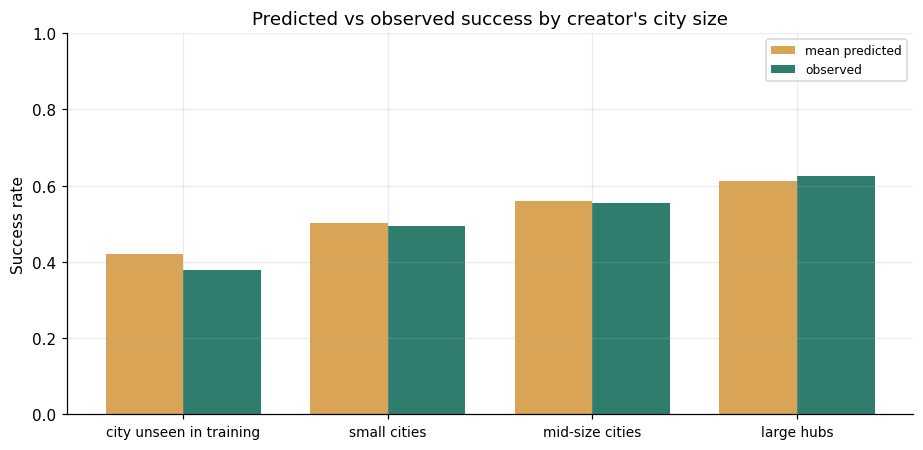

In [8]:
big = fair[fair["campaigns"] >= 100]
worst = big["gap (pts)"].abs().max()
check("Calibrated within 5 points in every city-size group", worst <= 5,
      f"largest group gap {worst:.1f} pts across {len(big)} groups of 100+ campaigns")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(fair)); w = 0.38
ax.bar(x - w / 2, fair["mean predicted"], w, color=SAND, label="mean predicted")
ax.bar(x + w / 2, fair["observed success"], w, color=TEAL, label="observed")
ax.set_xticks(x); ax.set_xticklabels(fair["city group"], fontsize=9)
ax.set_ylabel("Success rate"); ax.set_ylim(0, 1)
ax.set_title("Predicted vs observed success by creator's city size")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_fairness_city.png", dpi=130, bbox_inches="tight")
plt.show()

### What does the city feature buy?

The model is calibrated in every group, so it is not *wrong* for small-city
creators. But the High-risk label lands on them far more often. Refit the
same model without the city-density feature to see what the feature is worth
and what dropping it would change.

In [9]:
from sklearn.metrics import accuracy_score
from src.modeling import make_models

keep = [c for c in rec.X_train.columns if c != "log_city_project_count"]
m_nc = make_final_model()
m_nc.fit(rec.X_train[keep], train["success"])
p_nc = m_nc.predict_proba(X_te[keep])[:, 1]
y_all = test["success"].to_numpy()

def high_share(p, g):
    return float(np.mean(p[(tt["city_group"] == g).to_numpy()] < BANDS[0][0]))

cmp = pd.DataFrame([
    {"model": "with city density (final)",
     "accuracy": accuracy_score(y_all, rec.holdout_p >= 0.5),
     "ROC-AUC": roc_auc_score(y_all, rec.holdout_p),
     "High risk: small cities": high_share(rec.holdout_p, "small cities"),
     "High risk: large hubs": high_share(rec.holdout_p, "large hubs")},
    {"model": "without city density",
     "accuracy": accuracy_score(y_all, p_nc >= 0.5),
     "ROC-AUC": roc_auc_score(y_all, p_nc),
     "High risk: small cities": high_share(p_nc, "small cities"),
     "High risk: large hubs": high_share(p_nc, "large hubs")},
])
cmp.round(3)

,model,accuracy,ROC-AUC,High risk: small cities,High risk: large hubs
0,with city density (final),0.719,0.780,0.291,0.157
1,without city density,0.715,0.775,0.251,0.197


In [10]:
tt.groupby("city_group").agg(
    campaigns=("p", "size"), median_goal=("goal", "median"),
    median_tiers=("levels", "median"),
    share_4_or_fewer_tiers=("levels", lambda x: (x <= 4).mean()),
    share_over_45_days=("duration_days", lambda x: (x > 45).mean())).loc[
    [g for g in order if (tt["city_group"] == g).any()]].round(3)

,campaigns,median_goal,median_tiers,share_4_or_fewer_tiers,share_over_45_days
city_group,,,,,
city unseen in training,453,4000.0,7.0,0.227,0.265
small cities,2408,3000.0,7.0,0.163,0.266
mid-size cities,2407,3500.0,8.0,0.153,0.283
large hubs,2408,4500.0,8.0,0.144,0.299


**Reading the fairness results.**

- **Calibration parity broadly holds.** For creators in cities the model has
  seen, the average prediction is within about 1.5 points of what actually
  happened. The exception is **cities unseen in training** (453 campaigns):
  the model is 4.4 points too optimistic there — inside the 5-point limit,
  but the group to watch.
- **But the label does not land evenly.** Small-city creators are scored High
  risk almost twice as often as those in large hubs (29% against 16%). That
  reflects a real gap in outcomes (about 49% against 63% succeeded), not a
  modelling error, and the success rate among campaigns labelled High risk is
  similar for small, mid-size and large cities (roughly 19–24%).
- **Dropping the city feature narrows the gap but does not close it.** It
  costs about 0.4 points of accuracy and 0.5 points of AUC, and moves the
  High-risk share from 29% to 25% for small cities and from 16% to 20% for
  large hubs. The remainder is **not** explained by goal size or duration —
  small-city campaigns actually ask for *less* and run no longer — and tier
  counts differ only slightly (a median of 7 against 8).
- **It is a judgement call, and it is the team's to make.** City size is not
  something a creator can change, and the engine never advises on it. The
  benefit of the feature is small enough that dropping it would be a
  defensible choice. The prototype currently keeps it; this is documented as
  a limitation and an open option.

## 15.5 Does every lever move the prediction the right way?

**Pass condition:** each candidate change raises the predicted chance for at
least 99% of the held-out campaigns it applies to. (Effects are estimated the
way the prototype estimates them: the advisor's change in points added to the
Random Forest's score.)

In [11]:
raw_test = test[RAW_COLUMNS].copy()

def share_raised(lever, value, rows):
    before = rec.predict_proba(rows)
    after = rec.what_if_proba(rows, rec.apply_lever(rows, lever, value), base=before)
    return float(np.mean(after > before)), len(rows)

recs = []
for f in GOAL_FACTORS:
    s, n = share_raised("goal", f, raw_test)
    recs.append({"lever": "goal", "change": f"x {f}", "campaigns": n, "share raised": s})
dur = raw_test["duration"]
for t_ in sorted(DURATION_TARGETS, reverse=True):
    rows = raw_test[(dur > DEFAULT_DURATION[1]) & (dur <= 60) & (dur > t_ + 0.5)]
    s, n = share_raised("duration", t_, rows)
    recs.append({"lever": "duration", "change": f"to {t_} days", "campaigns": n, "share raised": s})
for t_ in TIER_TARGETS:
    rows = raw_test[raw_test["levels"] <= t_ - MIN_TIER_ADDITION]
    rows = rows.sample(min(2000, len(rows)), random_state=0)
    s, n = share_raised("reward tiers", t_, rows)
    recs.append({"lever": "reward tiers", "change": f"to {t_} tiers", "campaigns": n, "share raised": s})
direction = pd.DataFrame(recs)
direction.round(4)

,lever,change,campaigns,share raised
0,goal,x 0.9,7676,0.9991
1,goal,x 0.75,7676,0.9991
2,goal,x 0.6,7676,0.9988
3,goal,x 0.5,7676,0.9987
4,duration,to 45 days,1247,1.0000
5,duration,to 35 days,2505,1.0000
6,duration,to 28 days,3287,1.0000
7,reward tiers,to 6 tiers,1211,0.9983
8,reward tiers,to 8 tiers,2000,1.0000
9,reward tiers,to 10 tiers,2000,1.0000


In [12]:
worst_share = direction["share raised"].min()
check("Every lever raises the prediction for 99%+ of eligible campaigns", worst_share >= 0.99,
      f"lowest share raised across {len(direction)} candidate changes: {worst_share:.1%}")

PASS  Every lever raises the prediction for 99%+ of eligible campaigns
      lowest share raised across 10 candidate changes: 99.8%


## 15.6 Is the evidence behind the levers stable over time?

The levers rest on patterns in the data. If a pattern held only in the early
years, advice built on it would be fitted to history. Split by **time** —
earlier campaigns against later ones — and re-check each pattern within goal
quartiles, using the earlier period's quartile cut-points for both.

**Pass condition:** in both periods and every goal quartile, (a) success
rises with the tier band, (b) exactly-30-day campaigns do worse than both
shorter and slightly longer ones, and (c) campaigns over 45 days are the
worst duration group.

In [13]:
cuts = train_c["goal"].quantile([0.25, 0.5, 0.75]).to_numpy()
def prep(df):
    d = df.copy()
    d["gq"] = pd.cut(d["goal"], [-np.inf, *cuts, np.inf], labels=["Q1", "Q2", "Q3", "Q4"])
    d["tier_b"] = pd.cut(d["levels"], [0, 4, 7, 10, 100], labels=["<=4", "5-7", "8-10", "11+"])
    d["dur_b"] = pd.cut(d["duration_days"], [0, 29.5, 30.5, 45, 100],
                        labels=["<=29", "30", "31-45", ">45"])
    return d

periods = {"earlier": prep(train_c), "later": prep(test_c)}
stab_rows, tables = [], {}
for name, d in periods.items():
    tier = d.pivot_table(index="gq", columns="tier_b", values="success", aggfunc="mean", observed=False)
    durp = d.pivot_table(index="gq", columns="dur_b", values="success", aggfunc="mean", observed=False)
    tables[name] = (tier, durp)
    stab_rows.append({
        "period": name,
        "campaigns": len(d),
        "(a) tiers rise in every quartile": bool(tier.apply(lambda r: r.dropna().is_monotonic_increasing, axis=1).all()),
        "(b) 30-day is a dip in every quartile": bool(((durp["30"] < durp["<=29"]) & (durp["30"] < durp["31-45"])).all()),
        "(c) >45 days worst in every quartile": bool((durp[">45"] == durp.min(axis=1)).all()),
    })
stability = pd.DataFrame(stab_rows)
stability

,period,campaigns,(a) tiers rise in every quartile,(b) 30-day is a dip in every quartile,(c) >45 days worst in every quartile
0,earlier,30702,True,True,True
1,later,7676,True,True,True


In [14]:
for name, (tier, durp) in tables.items():
    print(f"=== {name.upper()}: success by tier band, within goal quartile ===")
    print(tier.round(3).to_string())
    print(f"\n=== {name.upper()}: success by duration, within goal quartile ===")
    print(durp.round(3).to_string()); print()

=== EARLIER: success by tier band, within goal quartile ===
tier_b    <=4    5-7   8-10    11+
gq                                
Q1      0.615  0.691  0.726  0.782
Q2      0.413  0.617  0.680  0.776
Q3      0.205  0.454  0.588  0.694
Q4      0.091  0.243  0.372  0.524

=== EARLIER: success by duration, within goal quartile ===
dur_b   <=29     30  31-45    >45
gq                               
Q1     0.746  0.657  0.726  0.607
Q2     0.723  0.603  0.674  0.562
Q3     0.636  0.497  0.602  0.460
Q4     0.445  0.354  0.412  0.314

=== LATER: success by tier band, within goal quartile ===
tier_b    <=4    5-7   8-10    11+
gq                                
Q1      0.604  0.694  0.767  0.813
Q2      0.339  0.599  0.730  0.818
Q3      0.160  0.453  0.575  0.702
Q4      0.020  0.192  0.357  0.501

=== LATER: success by duration, within goal quartile ===
dur_b   <=29     30  31-45    >45
gq                               
Q1     0.762  0.641  0.698  0.633
Q2     0.733  0.609  0.664  0.469
Q3 

In [15]:
for col in ["(a) tiers rise in every quartile", "(b) 30-day is a dip in every quartile",
            "(c) >45 days worst in every quartile"]:
    check(f"Pattern stable across periods: {col[4:]}", bool(stability[col].all()),
          "earlier: " + str(bool(stability.loc[0, col])) + ", later: " + str(bool(stability.loc[1, col])))

PASS  Pattern stable across periods: tiers rise in every quartile
      earlier: True, later: True
PASS  Pattern stable across periods: 30-day is a dip in every quartile
      earlier: True, later: True
PASS  Pattern stable across periods: >45 days worst in every quartile
      earlier: True, later: True


## 15.7 How do the recommendations behave on at-risk campaigns?

Replay the engine on a random sample of held-out campaigns it scored High or
Moderate risk. **Pass condition:** no plan lowers a campaign's predicted
chance. Everything else here is *reported*, not graded — including the
share of plans where the lower goal reduces the funding floor, because that
is a cost the creator should know about.

In [16]:
pool = test[(rec.holdout_p < BANDS[1][0]) & (test["duration_days"] <= 60)]
sample = pool.sample(250, random_state=11)
rows = []
for _, r in sample.iterrows():
    a = rec.assess(campaign_from_row(r))
    adv = tuple(a.options.loc[a.options["recommended"], "lever"]) if len(a.options) else ()
    plan_p = a.plan["probability"] if a.plan else a.probability
    cut = (1 - a.plan["goal"] / a.campaign["goal"]) if (a.plan and a.plan["goal"] < a.campaign["goal"]) else 0.0
    rows.append({"p": a.probability, "plan_p": plan_p, "gain": (plan_p - a.probability) * 100,
                 "levers": adv, "n_levers": len(adv), "goal_cut": cut,
                 "floor_before": a.base_floor,
                 "floor_after": a.plan["funding_floor"] if a.plan else a.base_floor,
                 "band_before": a.band, "band_after": rec.band_of(plan_p),
                 "rf_direct": rec.probability(a.plan["campaign"]) if a.plan else a.probability})
plans = pd.DataFrame(rows)

order_b = [n for _, n in BANDS]
moved = (plans["band_after"].map(order_b.index) > plans["band_before"].map(order_b.index))
cut = plans.loc[plans["goal_cut"] > 0, "goal_cut"]
summary = pd.Series({
    "campaigns replayed": len(plans),
    "received at least one recommendation": f"{(plans['n_levers'] > 0).mean():.0%}",
    "mean plan gain (pts)": round(plans["gain"].mean(), 1),
    "median plan gain (pts)": round(plans["gain"].median(), 1),
    "smallest plan gain (pts)": round(plans["gain"].min(), 1),
    "plans that reach a better risk band": f"{moved.mean():.0%}",
    "plans that reach 50% or more": f"{(plans['plan_p'] >= 0.5).mean():.0%}",
    "plans that cut the goal": f"{(plans['goal_cut'] > 0).mean():.0%}",
    "median goal cut among those": f"{cut.median():.0%}" if len(cut) else "n/a",
    "plans where goal x probability FALLS": f"{(plans['floor_after'] < plans['floor_before']).mean():.0%}",
    "RF re-scoring the plan directly: median gain (pts)": round(((plans['rf_direct'] - plans['p']) * 100).median(), 1),
    "RF re-scoring the plan directly: share that also rise": f"{(plans['rf_direct'] > plans['p']).mean():.0%}",
})
summary.to_frame("value")

,value
campaigns replayed,250
received at least one recommendation,100%
mean plan gain (pts),15.2
median plan gain (pts),13.6
smallest plan gain (pts),0.0
plans that reach a better risk band,59%
plans that reach 50% or more,42%
plans that cut the goal,95%
median goal cut among those,25%
plans where goal x probability FALLS,32%


Lever combinations recommended:
goal, reward tiers              99
goal, duration, reward tiers    65
goal                            37
goal, duration                  37
duration, reward tiers           6
reward tiers                     5
none                             1


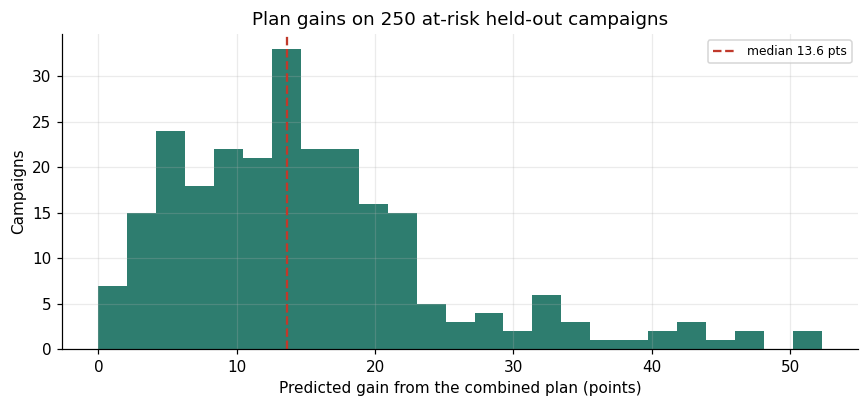

In [17]:
print("Lever combinations recommended:")
print(pd.Series([", ".join(l) if l else "none" for l in plans["levers"]]).value_counts().to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(plans["gain"], bins=25, color=TEAL)
ax.axvline(plans["gain"].median(), color=CORAL, ls="--", label=f"median {plans['gain'].median():.1f} pts")
ax.set_xlabel("Predicted gain from the combined plan (points)"); ax.set_ylabel("Campaigns")
ax.set_title("Plan gains on 250 at-risk held-out campaigns"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_plan_gains.png", dpi=130, bbox_inches="tight")
plt.show()

In [18]:
got_plan = plans[plans["n_levers"] > 0]
check("No plan lowers a campaign's predicted chance", bool((plans["gain"] >= 0).all()),
      f"smallest gain among the {len(got_plan)} campaigns that received a plan: "
      f"{got_plan['gain'].min():+.1f} pts ({len(plans) - len(got_plan)} got none)")

PASS  No plan lowers a campaign's predicted chance
      smallest gain among the 249 campaigns that received a plan: +2.0 pts (1 got none)


**What the replay shows.**

- **Every at-risk campaign but one gets advice** (the exception is a case
  where no single change cleared the 2-point bar).
- **The typical plan adds roughly 14 points**, and about four plans in ten
  take a campaign to 50% or better. These are the engine's own estimates:
  they describe what the models expect, not what would happen.
- **The two models agree.** Re-scoring every planned campaign directly with
  the Random Forest also raises its chance in **all 250 cases**, by a median
  of about 15 points against the engine's 13.6. The advisor sets the
  direction and size of each change; the final model independently confirms
  the plans help.
- **Most plans involve a goal cut, usually of 25%.**
- **The cost the creator should know about:** in about three plans in ten,
  goal x probability **falls**. The lower goal reduces what a successful
  campaign raises by more than the better odds make up for. The report
  already states what a lower goal gives up, and this is why that line is
  not optional.
- A minimum gain of zero appears only because one campaign received no plan;
  no plan makes a campaign worse.

## 15.8 All checks

In [19]:
results = pd.DataFrame(checks)
results["result"] = np.where(results["passed"], "PASS", "FAIL")
print(f"{int(results['passed'].sum())} of {len(results)} checks passed\n")
results[["result", "check", "detail"]]

15 of 16 checks passed



,result,check,detail
0,PASS,No post-launch column among the model's features,137 features inspected; offending: none
1,PASS,No post-launch field among the prototype's inputs,"inputs are ['goal', 'duration', 'levels', 'rew..."
2,PASS,Every post-launch field is refused,"7 of 7 refused: ['backers', 'comments', 'funde..."
3,PASS,"Timing features come from the launch date, not...",launch_date = end_date - duration holds exactl...
4,PASS,What-if engine rebuilds the training matrix ex...,2000 rows re-featurised from raw inputs; max d...
5,PASS,Reproduces the Milestone 3 model (random split),"differences from Milestone 3: accuracy 0.0000,..."
6,PASS,Holds up on later campaigns (chronological split),accuracy 0.719 random vs 0.720 chronological (...
7,PASS,Calibrated within 5 points per decile (random ...,largest gap 3.4 pts
8,FAIL,Calibrated within 5 points per decile (chronol...,largest gap 6.5 pts
9,PASS,Risk bands are ordered by observed success,"observed success by band: High risk 19.7%, Mod..."


In [20]:
Path("../reports/m4_validation_summary.json").write_text(json.dumps(
    {"checks_passed": int(results["passed"].sum()), "checks_total": int(len(results)),
     "checks": checks}, indent=2))
fair.round(4).to_csv("../reports/m4_fairness_by_city.csv", index=False)
stability.to_csv("../reports/m4_lever_stability.csv", index=False)
direction.round(4).to_csv("../reports/m4_lever_direction.csv", index=False)
summary.to_frame("value").to_csv("../reports/m4_plan_behaviour.csv")
print("Wrote m4_validation_summary.json, m4_fairness_by_city, m4_lever_stability, "
      "m4_lever_direction, m4_plan_behaviour")

Wrote m4_validation_summary.json, m4_fairness_by_city, m4_lever_stability, m4_lever_direction, m4_plan_behaviour


## Task 15 — Summary

**15 of 16 checks pass.** The failure is reported, not hidden.

| Question | Answer |
|---|---|
| Launch-time information only? | **Yes** - no post-launch column in the 137 features, none among the inputs, and all seven post-launch fields refused if offered |
| Is the model the one from Milestone 3? | **Yes** - the calibrated Random Forest's accuracy, F1 and ROC-AUC match the model card to four decimal places |
| Does it hold on later campaigns? | **Yes on accuracy** (0.719 vs 0.720), **but** calibration slips in the lowest decile on the chronological split: **FAIL** (6.5 points against a 5-point limit) |
| Are probabilities calibrated? | Yes on the random split (worst decile 3.4 points); optimistic for the riskiest campaigns on later data |
| Fair across city size? | Calibrated in every group (within 4.4 points; about 1.5 for cities seen in training), **but** small-city creators are flagged High risk ~1.9x as often - a documented judgement call |
| Do levers move predictions the right way? | Yes - 99.8% or more for every candidate change |
| Is the evidence stable over time? | **Yes** - the tier gradient, the 30-day dip and the long-campaign penalty all hold in both periods and every goal quartile |
| Do plans behave sensibly? | No plan lowers a chance, and the Random Forest confirms every plan when re-scoring it directly; **but ~3 in 10 lower goal x probability** |

### What this validation cannot show

- **That following the advice works.** Every check here is about the model
  and the engine behaving consistently. None can show that a creator who
  adds reward tiers or trims a goal would actually do better, because the
  data contains no campaign that changed one thing and was observed again.
- **That the tier effect is causal.** It is the strongest and most stable
  pattern in the data, which is exactly why it dominates the advice, and it
  is also the one most plausibly driven by creators who plan carefully.
- **That it works today.** Everything is 2009-2012, and the calibration
  slip on later data suggests the model was already ageing within that
  window.
- **That it is useful to creators.** Nobody outside the team has used it.

### Handoff to the December wrap-up

`15_final_charts.ipynb` turns the strongest results into presentation-ready
figures, and the README and presentation outline summarise them.